![logo](https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/Helmholtz-AI.png?raw=true)

# Explainability for Convolutional Neural Networks

In this notebook we will show you different methods that can be used for interpreting CNN models. We will demonstrate you how to compare those methods and choose the appropriate one.

---

## Getting Started

### Setup Colab environment

If you installed the packages and requirements on your own machine, you can skip this section and start from the import section.
Otherwise, you can follow and execute the tutorial on your browser. In order to start working on the notebook, click on the following button. This will open this page in the Colab environment, and you will be able to execute the code on your own.

<a href="https://colab.research.google.com/github/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/2026-HIDA-Autumn/xai-for-cnn/5-Tutorial_XAI_for_ImageAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Now that you opened the notebook in Colab, run the next cell. It fetches the tutorials and installs the requirements.

**Note:** Google Colab may ask you to restart the runtime after installing the required packages. If prompted, restart the runtime before continuing with the notebook.

Running the notebook locally, that cell does nothing: you already have the repository and the requirements.

In [1]:
# On Google Colab: fetch the course and install the requirements.
# Running locally this cell does nothing, because you already have the repository
# and installed the requirements yourself.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %cd /content
    !rm -rf XAI-Tutorials
    !git clone --depth 1 --branch 2026-HIDA-Autumn https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials.git
    %cd XAI-Tutorials
    !pip install -r requirements_xai-for-cnn.txt
    %cd xai-for-cnn


### Imports

Let's start with importing all required Python packages.

In [2]:
# Load the required packages
import json
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

import shap
from lime import lime_image

import torch
from torchvision import models
from torchvision.models.inception import Inception_V3_Weights
from skimage.segmentation import mark_boundaries

import sys
sys.path.append('./')
import utils

sys.path.append('../models/')
from model_gradcam import GradCamModel

We fix the random seeds to ensure reproducible results, as we work with (pseudo) random numbers.

In [3]:
# assert reproducible random number generation
seed = 1
np.random.seed(seed)
torch.manual_seed(seed)

---

## Data and Model Loading

We first load the image we want to analyse and the model we use for prediction.

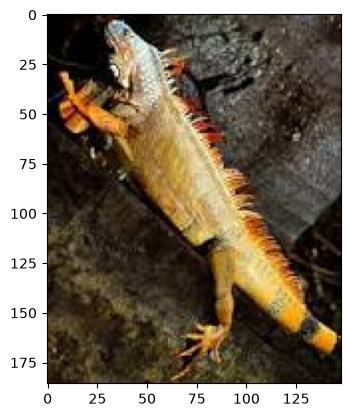

In [4]:
# read and visualize the image
path_to_img = '../data/images/Iguana.jpeg'
img = utils.read_image_cv(path_to_img)
img_PIL = utils.read_image_PIL(path_to_img)
plt.imshow(img)
plt.show()

# load the ImageNet class names
url = "https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json"
fname = shap.datasets.cache(url)
with open(fname) as f:
    class_names = json.load(f)

Before we can use the image, we need to convert the image to RGB channel, transform the image (convert to PIL format, resize to lower resolution, convert to tensor dtype and normalize the pixel values), and unsqueeze the image to add a batch dimension.

In [5]:
# define the transformations (here we are using the ImageNet transformations)
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

img_trans = utils.transform_img(img, mean, std)

We define a CNN model that we will use for the classification using the ResNet50 architecture.

In [6]:
# load model
model_shap = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1).eval()
model_lime = models.inception_v3(weights=Inception_V3_Weights.DEFAULT)
model_gc = GradCamModel().eval()

## Now, what are our possibilities to explain the classification of our image?

There are two main kinds of explainability methods for images:

- occlusion- or perturbation-based methods
- gradient-based methods

The first ones consist of manipulating/masking parts of the image to generate explanations. Some examples of these are LIME and SHAP.
The second one consists of leveraging the gradient of the function so that a mapping of the function value onto multiple input dimensions is readily obtained. There are many gradient-based methods (e.g. Grad-CAM, Integrated Gradients, SmoothGrad), which differ in how these gradients are computed.

In this tutorial, we will compare the results from Grad-CAM with the SHAP library, which combines perturbation- and gradient-based methods.

### Interpretation with GradCAM

In the [Tutorial_Grad-CAM_for_images.ipynb](./2-Tutorial_Grad-CAM_for_images.ipynb) notebook you were introduced to the model-specific Grad-CAM method. This method uses the gradients to localize the pixel in the image that are relevant for the classification, creating a heatmap that is very easy to interpret.

<font color='green'>

#### Task 1: Apply Grad-CAM to the trained ResNet50 model to explain the prediction for the iguana image. Compute the class activation (localization) map and visualize the resulting heatmap to highlight the image regions that contribute most to the prediction.

In [ ]:
# Step 1: Forward Pass
...

# Step 2: Select the Target Class
...


In [ ]:
...

# Step 3: Compute the Gradients
...

# Step 4: Compute the Grad-CAM
...

# Step 5: Post-processing
...

# Step 6: Plot Results
...


### Interpretation with LIME
In the [Tutorial_LIME_Images.ipynb](./4-Tutorial_LIME_Images.ipynb) we discussed how to use the LIME local interpretation method to explain the outcome of an image classification CNN model. This model uses a surrogate model trained on interpretable features obtained by perturbing the original image. Let's apply this method to our iguana image and comment on the explanations we get.

<font color='green'>

#### Task 2: Explain the ResNet50 prediction for the iguana image using LIME. Create the appropriate LIME explainer and visualize the image regions that contribute most to the model prediction.

In [ ]:
# Step 1: Transform image for LIME
...

# Step 2: Instantiate the explainer class
...

# Step 3: Plot explanations
...


<font color='green'>

#### Task 3 (Optional): As an additional exercise, investigate the other top predicted classes for the iguana image. Repeat the LIME analysis (repeat step 3 for different labels) for different predicted labels and evaluate whether the generated explanations provide meaningful and reliable insights for each class.

In [ ]:
# Step 1: Select top 3 classes and respective probabilities
...


In [ ]:
# Step 2: Plot explanations with explainer setup above for label 0, 1 and 2
...


In [ ]:
# Step 2: Plot explanations with explainer setup above for label 0, 1 and 2
...


In [ ]:
# Step 2: Plot explanations with explainer setup above for label 0, 1 and 2
...


### Interpretation with SHAP

In the [Tutorial_SHAP_Images.ipynb](5-Tutorial_SHAP_Images.ipynb) notebook you were introduced to the model-agnostic SHAP method. Recall, with SHAP we get contrastive explanations that compare the prediction with the baseline. 

*Note: it can take some time to compute the SHAP values.*

<font color='green'>

#### Task 4: Explain the ResNet50 prediction for the iguana image using SHAP. First, create a SHAP explainer directly on the model input to obtain pixel-level explanations. Then, create a second explainer using an intermediate convolutional layer (e.g. layer4) and compare the resulting explanations. Analyze how the highlighted image regions differ between both approaches.

> **Hint:** For CNN-based image models, SHAP explanations can either be computed directly on the input pixels or on intermediate convolutional feature maps. Explaining deeper layers such as `layer4` often produces smoother and more semantically meaningful explanations because these layers capture higher-level object features instead of individual pixels. You can specify a target layer by passing both the model and the layer to the explainer:
>
> ```python id="x8j4sn"
> shap.GradientExplainer((model, model.layer4), background_data)
> ```


In [ ]:
# Step 1. Select the background dataset for the baseline
...

# Step 2. Instantiate the explainer class
...

# Step 3. Compute SHAP values on custom image
...

# Step 4. Plot results

# Step 4.1: Get class names
...

# Step 4.2: Reshape SHAP values
...

        # Extract SHAP values for this class and remove singleton batch dimension
...

# Step 4.3: Transform image for plotting
...


In [ ]:
# Step 1. Select the background dataset for the baseline
...

# Step 2. Instantiate the explainer class
...

# Step 3. Compute SHAP values on custom image
...

# Step 4. Plot results

# Step 4.1: Get class names
...

# Step 4.2: Reshape SHAP values
...

        # Extract SHAP values for this class and remove singleton batch dimension
...

# Step 4.3: Transform image for plotting
...


<font color='green'>

#### Question 1: Think about the differences between the introduced explainability methods.

<font color='grey'>

#### Your Answer: 




## Further Reading

### Limitations of Explainability for Image Analysis

XAI methods can help us inspect model behaviour, but their explanations also require evaluation. A visually convincing heatmap is not sufficient evidence that it faithfully reflects the model’s behaviour. The following examples illustrate several limitations and ways to investigate them.

**Sanity checks for saliency maps**: Does an explanation depend on what the model has learned? [Adebayo et al. (2018)](https://proceedings.neurips.cc/paper_files/paper/2018/file/294a8ed24b1ad22ec2e7efea049b8737-Paper.pdf) investigate this by randomizing model parameters and by training models on randomly shuffled labels, then comparing the resulting explanations. Some methods continue to produce visually similar maps despite these changes. Their visual plausibility can therefore be misleading. In the section [Sanity Checks for Saliency Maps](https://xai-tutorials.readthedocs.io/en/latest/_xai_limitations/sanity_checks_saliency.html) you can watch a video and read more about the tests and their interpretation. Passing these checks is useful evidence, but does not establish that an explanation is faithful in every respect or robust to adversarial attacks.

**Relevance and resistance of saliency maps**: According to the paper from [Zhang et al., 2022](https://link.springer.com/chapter/10.1007/978-3-031-16437-8_43), these two properties of saliency maps should be taken into consideration in future works to validate the trustworthiness of medical AI explainability. As shown in the picture below, different predictions might have similar or same saliency maps (lack of relevance) or the same predictions might have different saliency maps (lack of resistance).

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/raw/main/docs/source/_figures/relevance_resistance.png" width="800" /></center>

  
**Saliency Maps Can Be Misleading**: In the paper of [Rudin et al., 2018](https://arxiv.org/abs/1811.10154) the author underlines how saliency maps are often considered to be explanatory. Saliency maps can be useful to determine what part of the image is being omitted by the classifier, but this leaves out all information about how relevant information is being used. Knowing which regions a saliency method highlights within the image does not tell the user what it is doing with that part of the image, as illustrated in the figure below. In fact, the saliency maps for multiple classes could be essentially the same; in that case, the explanation for why the image might contain a Siberian husky would be the same as the explanation for why the image might contain a transverse flute.
  
<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/raw/main/docs/source/_figures/Husky.png" width="800" /></center>

  
**Disagreement Problem**: As shown in the paper of [Krishna et al., 2022](https://arxiv.org/abs/2202.01602) different methods can lead to different explanations, and it's important to question which one we should consider more reliable for our task at hand.

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/raw/main/docs/source/_figures/comparison.png" width="800" /></center>

### Investigating Adversarial Attacks with XAI

An **adversarial attack** ([Goodfellow et al., 2014](https://arxiv.org/abs/1406.2661)) consists of subtly modifying an original image in such a way that the changes are almost undetectable to the human eye. The modified image is called an adversarial image, and, when submitted to a classifier, is misclassified, while the original one is correctly classified.

</center>
<img src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*PmCgcjO3sr3CPPaCpy5Fgw.png" width="800"/>
</center>
<font size=1> Source: [Goodfellow et al., 2014](https://arxiv.org/abs/1412.6572)

<font color='green'>

#### Question 3: Can you think about some situations where these adversarial attacks could be very dangerous?

<font color='grey'>

#### Your Answer: 




The following example from [Klawikowska et al., 2020](https://link.springer.com/chapter/10.1007/978-3-030-61401-0_14) illustrates how explanation maps can help us investigate model behaviour before and after adversarial attacks.

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/raw/main/docs/source/_figures/adversarial_attacks_and_xai.png" width="800" /></center>

Panel a) shows the original image, which the model correctly classifies as a cat. Panels b) and d) show examples attacked using the Fast Gradient Sign Method (FGSM) and a pixel-level attack. The attacks change the predicted class, and the corresponding explanation maps also change. These differences can provide clues for further investigation, but the examples do not establish that heatmaps reliably detect adversarial attacks.

Panels c) and e) illustrate results after **adversarial retraining**. Here, training on adversarial examples is the intervention intended to improve robustness. The explanation maps help us inspect its effects; producing an explanation does not itself protect the classifier.

**Can we trust the explanation?**

The limitations discussed earlier also apply here. As shown in Sanity Checks for Saliency Maps, a visually convincing map may fail to reflect what the model has learned. Passing these checks, however, does not establish resistance to adversarial manipulation.

Attacks can also target explanations themselves. [Ghorbani et al., 2019](https://ojs.aaai.org/index.php/AAAI/article/view/4252) show that small input perturbations can substantially change explanations while preserving the predicted label. Conversely, [Subramanya et al., 2019](https://openaccess.thecvf.com/content_ICCV_2019/html/Subramanya_Fooling_Network_Interpretation_in_Image_Classification_ICCV_2019_paper.html) demonstrate adversarial patches that cause misclassification while avoiding being highlighted by Grad-CAM.

**Takeaway:** XAI can support the investigation of adversarial attacks and the evaluation of countermeasures. However, an unusual heatmap does not prove that an attack occurred, and a plausible heatmap does not prove that a prediction is trustworthy.

For further reading, see the survey by [Baniecki and Biecek, 2024](https://arxiv.org/abs/2306.06123).